# Исследование территории Магнитогорска с помощью BlocksNet 1.0.0.a9

Этот ноутбук повторяет учебный пайплайн BlocksNet: загружает данные OpenStreetMap, нарезает город на кварталы, назначает функциональные зоны, строит пешеходный граф, считает матрицу доступности, агрегирует здания и школы, а затем рассчитывает показатели обеспеченности, плотности, морфотипов и доступности.

**Важно:** ноутбук рассчитан на самостоятельный последовательный запуск. Он не требует ручной проверки или согласования промежуточных таблиц: все проверки выполняются кодом, а при проблеме выводится понятное сообщение.

## Что понадобится

Перед первым запуском установите зависимости проекта из корня репозитория:

```powershell
.venv\Scripts\python.exe -m pip install -e .
```

Если Jupyter не видит окружение, зарегистрируйте ядро:

```powershell
.venv\Scripts\python.exe -m ipykernel install --user --name magnitogorsk --display-name "Python (magnitogorsk)"
```

## Что будет скачано при запуске

- граница Магнитогорска через Nominatim/OSM;
- дороги, железные дороги, вода и функциональные зоны через Overpass/OSM;
- здания и школы через Overpass/OSM;
- пешеходный граф через IduEdu/OSM.

Все результаты сохраняются в `examples/data_magnitogorsk/`. При повторном запуске готовые файлы читаются с диска, поэтому повторно скачивать данные не нужно.

## Единицы измерения

- расстояния и площади — метры и квадратные метры;
- время в матрице доступности — минуты;
- население — человеко-места/люди (оценочно);
- ёмкость школ — места;
- обеспеченность — доля от 0 до 1;
- FSI, GSI, MXI, OSR — безразмерные коэффициенты;
- L — средняя этажность.

## 0. Настройки, импорты и вспомогательные функции

Здесь задаются пути, тип графа и единые правила сохранения. Все таблицы с геометрией сохраняются в GeoJSON, а обычные таблицы — в CSV и Parquet.

In [2]:
from __future__ import annotations

import json
import pickle
import warnings
from datetime import datetime, timezone
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd
from shapely.validation import make_valid

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)
ox.settings.use_cache = True
ox.settings.log_console = False

BASE_DIR = Path.cwd()
EXAMPLES_DIR = BASE_DIR / "examples" if (BASE_DIR / "examples").exists() else BASE_DIR
DATA_DIR = EXAMPLES_DIR / "data_magnitogorsk"
DATA_DIR.mkdir(parents=True, exist_ok=True)

CITY_QUERY = "Магнитогорск, Челябинская область, Россия"
CRS_WGS84 = "EPSG:4326"
GRAPH_TYPE = "walk"
WALK_SPEED_KMH = 5.0
MIN_BLOCK_AREA_M2 = 100.0
MAX_CSV_CELLS = 40_000_000

print("Папка результатов:", DATA_DIR.resolve())
print("Тип графа:", GRAPH_TYPE, "| скорость:", WALK_SPEED_KMH, "км/ч")


def json_safe(value):
    """Приводит значение к типу, который можно записать в GeoJSON/CSV."""
    if value is None:
        return None
    if hasattr(value, "value"):
        value = value.value
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, (list, tuple, dict, set)):
        return json.dumps(value, ensure_ascii=False, default=str)
    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass
    return value


def save_gdf(gdf, name, index_col=None):
    path = DATA_DIR / f"{name}.geojson"
    out = gdf.copy()
    out = out[out.geometry.notna() & ~out.geometry.is_empty]
    if index_col is not None:
        out = out.reset_index()
        if "index" in out.columns:
            out = out.rename(columns={"index": index_col})
    geometry_name = out.geometry.name
    for column in out.columns:
        if column == geometry_name:
            continue
        out[column] = out[column].map(json_safe)
    out.to_file(path, driver="GeoJSON", encoding="utf-8")
    print(f"Сохранено: {path.name} ({len(out)} объектов)")


def load_gdf(name, index_col=None):
    path = DATA_DIR / f"{name}.geojson"
    gdf = gpd.read_file(path)
    if index_col is not None and index_col in gdf.columns:
        gdf = gdf.set_index(index_col)
        gdf.index = gdf.index.astype(int)
    print(f"Загружено: {path.name} ({len(gdf)} объектов)")
    return gdf


def save_table(df, name):
    out = df.copy()
    for column in out.columns:
        if out[column].dtype == object:
            out[column] = out[column].map(json_safe)
    csv_path = DATA_DIR / f"{name}.csv"
    if out.size <= MAX_CSV_CELLS:
        out.to_csv(csv_path, encoding="utf-8")
        print(f"Сохранено: {csv_path.name}")
    else:
        print(f"CSV не сохранён: таблица слишком большая ({out.size} ячеек)")
    parquet_path = DATA_DIR / f"{name}.parquet"
    try:
        out.to_parquet(parquet_path)
        print(f"Сохранено: {parquet_path.name}")
    except Exception as exc:
        print(f"Parquet не сохранён ({name}): {exc}")


def require(condition, message):
    if not condition:
        raise RuntimeError(message)

Папка результатов: C:\Users\lenovo\Desktop\вуз\итмо\ИИ\python-package-boilerplate\examples\data_magnitogorsk
Тип графа: walk | скорость: 5.0 км/ч


## 1. Граница Магнитогорска

**Что делаем:** получаем административную границу города и приводим её к одной проекции.

**Зачем:** граница нужна как территория исследования и как рамка для нарезки кварталов.

**Что проверяем:** граница должна быть полигоном, а её площадь — быть правдоподобной для Магнитогорска.

In [5]:
boundary_path = DATA_DIR / "boundaries.geojson"
if boundary_path.exists():
    boundaries = load_gdf("boundaries")
else:
    boundaries = ox.geocode_to_gdf(CITY_QUERY)
    if boundaries.empty or not boundaries.geom_type.isin(["Polygon", "MultiPolygon"]).any():
        print("Геокодер вернул не полигон, пробуем OSM relation R10185071")
        boundaries = ox.geocode_to_gdf("R10185071")
    require(not boundaries.empty, "Не удалось получить границу Магнитогорска")
    boundaries = boundaries[boundaries.geom_type.isin(["Polygon", "MultiPolygon"])][["geometry"]].copy()
    boundaries["geometry"] = boundaries.geometry.apply(make_valid)
    boundaries = boundaries.dissolve().reset_index(drop=True).to_crs(CRS_WGS84)
    save_gdf(boundaries, "boundaries")

boundaries = boundaries[boundaries.geom_type.isin(["Polygon", "MultiPolygon"])][["geometry"]].copy()
boundaries["geometry"] = boundaries.geometry.apply(make_valid)
boundaries = boundaries.dissolve().reset_index(drop=True).to_crs(CRS_WGS84)

CRS_PROJECTED = boundaries.estimate_utm_crs()
boundaries_projected = boundaries.to_crs(CRS_PROJECTED)

area_km2 = boundaries_projected.area.sum() / 1_000_000
print(f"Граница: {len(boundaries)} полигон(ов), площадь {area_km2:.1f} км²")
print("Проекция для расчётов:", CRS_PROJECTED)
require(10 < area_km2 < 5000, "Площадь границы выглядит подозрительно — проверьте запрос города")

Загружено: boundaries.geojson (1 объектов)
Граница: 1 полигон(ов), площадь 340.4 км²
Проекция для расчётов: EPSG:32640


## 2. Загрузка объектов OpenStreetMap

**Что делаем:** воду и дороги берём из уже сохранённых GeoJSON, а железные дороги — из локального PBF-экстракта Geofabrik.

**Скачайте:** [ural-fed-district-latest.osm.pbf](https://download.geofabrik.de/russia/ural-fed-district-latest.osm.pbf) (~378 МБ).

**Куда положить:** `examples/data_magnitogorsk/ural-fed-district-latest.osm.pbf` (распаковывать не нужно).

**Ячейка ниже:** читает только объекты `railway=rail`, обрезает их по границе Магнитогорска и сохраняет `railways.geojson`. Вода и дороги повторно не скачиваются.

**Что проверяем:** слои не пустые, геометрии валидны, все объекты приведены к проекции города.

In [ ]:
import time

import geopandas as gpd
import osmnx as ox
import pyogrio


bc_tags = {
    "roads": {
        "highway": [
            "construction",
            "crossing",
            "living_street",
            "motorway",
            "motorway_link",
            "motorway_junction",
            "pedestrian",
            "primary",
            "primary_link",
            "raceway",
            "residential",
            "road",
            "secondary",
            "secondary_link",
            "services",
            "tertiary",
            "tertiary_link",
            "track",
            "trunk",
            "trunk_link",
            "turning_circle",
            "turning_loop",
            "unclassified",
        ],
        "service": ["living_street", "emergency_access"],
    },
    "water": {
        "riverbank": True,
        "reservoir": True,
        "basin": True,
        "dock": True,
        "canal": True,
        "pond": True,
        "natural": ["water", "bay"],
        "waterway": ["river", "canal", "ditch"],
        "landuse": "basin",
        "water": "lake",
    },
}

boundaries_4326 = boundaries.to_crs(CRS_WGS84)

OVERPASS_SERVERS = [
    ("overpass-api.de", "https://overpass-api.de/api"),
    ("overpass.kumi.systems", "https://overpass.kumi.systems/api"),
    ("overpass.private.coffee", "https://overpass.private.coffee/api"),
]
OVERPASS_TIMEOUT_SECONDS = 180
OVERPASS_MAX_QUERY_AREA_SIZE = 10_000 * 10_000
OVERPASS_SPLIT_ROUNDS = 3
OVERPASS_RETRY_PAUSE_SECONDS = 5

ox.settings.requests_timeout = OVERPASS_TIMEOUT_SECONDS
ox.settings.overpass_rate_limit = False


def _download_osm_layer(polygon, tags):
    """Скачивает слой OSM с перебором серверов и дроблением области при сбоях."""
    initial_url = ox.settings.overpass_url
    initial_area_size = ox.settings.max_query_area_size
    area_size = OVERPASS_MAX_QUERY_AREA_SIZE
    last_error = None
    try:
        for split_round in range(OVERPASS_SPLIT_ROUNDS):
            ox.settings.max_query_area_size = area_size
            print(f"Круг {split_round + 1}: части запроса до {area_size / 1_000_000:.2f} км²")
            for server_name, server_url in OVERPASS_SERVERS:
                try:
                    ox.settings.overpass_url = server_url
                    print(f"  Запрос к {server_name}...")
                    result = ox.features_from_polygon(polygon, tags)
                    print(f"  Успешно: {server_name}, объектов {len(result)}")
                    return result
                except Exception as exc:
                    last_error = exc
                    print(f"  Не удалось ({server_name}): {type(exc).__name__}: {exc}")
                    time.sleep(OVERPASS_RETRY_PAUSE_SECONDS)
            area_size = max(area_size / 4, 1_000 * 1_000)
    finally:
        ox.settings.overpass_url = initial_url
        ox.settings.max_query_area_size = initial_area_size

    raise RuntimeError(
        "Не удалось скачать данные OSM ни с одного сервера Overpass. "
        "Проверьте интернет, VPN/прокси и повторите запуск позже."
    ) from last_error


def fetch_osm_layer(name, tags):
    path = DATA_DIR / f"{name}.geojson"
    if path.exists():
        gdf = load_gdf(name)
    else:
        gdf = _download_osm_layer(boundaries_4326.union_all(), tags)
        save_gdf(gdf, name)
    if gdf.empty:
        return gdf.to_crs(CRS_PROJECTED)
    return gdf.to_crs(CRS_PROJECTED)


def clean_geometries(gdf, allowed_types):
    if gdf.empty:
        return gdf
    gdf = gdf.copy()
    gdf["geometry"] = gdf.geometry.apply(make_valid)
    gdf = gdf[gdf.geom_type.isin(allowed_types)].copy()
    gdf = gdf[~gdf.geometry.is_empty].copy()
    return gdf.reset_index(drop=True)


water = fetch_osm_layer("water", bc_tags["water"])
roads = fetch_osm_layer("roads", bc_tags["roads"])

OSM_PBF_PATH = DATA_DIR / "ural-fed-district-latest.osm.pbf"
railways_path = DATA_DIR / "railways.geojson"

if railways_path.exists():
    railways = load_gdf("railways")
else:
    require(
        OSM_PBF_PATH.exists(),
        f"Не найден PBF: {OSM_PBF_PATH}. "
        "Скачайте https://download.geofabrik.de/russia/ural-fed-district-latest.osm.pbf "
        f"и положите файл в {DATA_DIR}",
    )
    print(f"Читаю железные дороги из {OSM_PBF_PATH.name}...")
    bbox = tuple(boundaries_4326.total_bounds)
    try:
        railways = pyogrio.read_dataframe(
            OSM_PBF_PATH,
            layer="lines",
            columns=["osm_id", "railway"],
            where="railway = 'rail'",
            bbox=bbox,
        )
    except Exception as exc:
        print(f"Фильтр PBF не сработал ({type(exc).__name__}: {exc}); читаю слой lines целиком")
        railways = pyogrio.read_dataframe(
            OSM_PBF_PATH,
            layer="lines",
            columns=["osm_id", "railway"],
            bbox=bbox,
        )
        if "railway" in railways.columns:
            railways = railways[railways["railway"] == "rail"].copy()
    if railways.crs is None:
        railways = railways.set_crs(CRS_WGS84)
    else:
        railways = railways.to_crs(CRS_WGS84)
    railways = gpd.clip(railways, boundaries_4326)
    railways = clean_geometries(railways, ["LineString", "MultiLineString"])
    require(not railways.empty, "В PBF не найдены железные дороги railway=rail в границах Магнитогорска")
    save_gdf(railways, "railways")

water = clean_geometries(water, ["Polygon", "MultiPolygon", "LineString", "MultiLineString"])
roads = clean_geometries(roads, ["LineString", "MultiLineString"])
railways = clean_geometries(railways, ["LineString", "MultiLineString"]).to_crs(CRS_PROJECTED)

print("Вода:", len(water))
print("Дороги:", len(roads))
print("Железные дороги:", len(railways))
require(not roads.empty, "Не удалось загрузить дороги — без них нельзя нарезать кварталы")

In [5]:
print("CRS:", roads.crs)
print("Типы геометрий:")
print(roads.geom_type.value_counts())

print("Пустых:", roads.is_empty.sum())
print("Некорректных:", (~roads.is_valid).sum())
print("Столбцы:", roads.columns.tolist())

CRS: EPSG:32640
Типы геометрий:
LineString    2910
Point         1170
Polygon          5
Name: count, dtype: int64
Пустых: 0
Некорректных: 0
Столбцы: ['element', 'id', 'button_operated', 'crossing', 'highway', 'tactile_paving', 'traffic_signals:sound', 'bicycle', 'horse', 'crossing:markings', 'crossing:island', 'traffic_calming', 'traffic_signals:vibration', 'check_date:crossing', 'leisure', 'sport', 'kerb', 'railway', 'name', 'service', 'maxspeed', 'crossing:signals', 'supervised', 'lanes', 'old_ref', 'oneway', 'ref', 'surface', 'alt_name:en', 'lit', 'name:en', 'name:etymology:wikidata', 'name:ru', 'int_name', 'postal_code', 'shoulder', 'sidewalk', 'bridge', 'layer', 'addr:postcode', 'lanes:backward', 'lanes:forward', 'addr:city', 'living_street', 'embankment', 'source', 'junction', 'addr:country', 'foot', 'overtaking', 'destination', 'destination:ref', 'hgv', 'agricultural', 'parking:left', 'parking:right', 'parking:right:orientation', 'loc_name', 'name:ba', 'access', 'lane_markings'

## 3. Нарезка кварталов

**Что делаем:** превращаем линии дорог, железных дорог и границы водоёмов в замкнутые полигоны — кварталы.

**Метрика:** площадь квартала в м². Слишком маленькие осколки меньше 100 м² отбрасываются, чтобы не мешать пространственным операциям.

**Что узнаём:** сколько в городе кварталов и как они распределены по площади.

2026-11-03 01:51:16.425 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema
2026-11-03 01:51:16.446 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema
2026-11-03 01:51:16.466 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema
2026-11-03 01:51:16.487 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:51 - Checking boundaries schema
2026-11-03 01:51:16.497 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:55 - Checking line objects schema
2026-11-03 01:51:16.534 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:62 - Checking polygon objects schema
2026-11-03 01:51:16.547 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:69 - Checking buildings schema
2026-11-03 01:51:16.548 

Дорожных линий: 2910
Железнодорожных линий: 3391


2026-11-03 01:51:16.918 | SUCCESS  | blocksnet.blocks.cutting.processing.core:cut_urban_blocks:26 - 2997 blocks are successfully cut


Сохранено: blocks_initial.geojson (2910 объектов)
Кварталов: 2910
Суммарная площадь кварталов: 317.34 км²
count    2.910000e+03
mean     1.090505e+05
std      7.352538e+05
min      1.007758e+02
25%      2.920684e+03
50%      1.212228e+04
75%      2.722261e+04
max      1.575312e+07
Name: site_area, dtype: float64


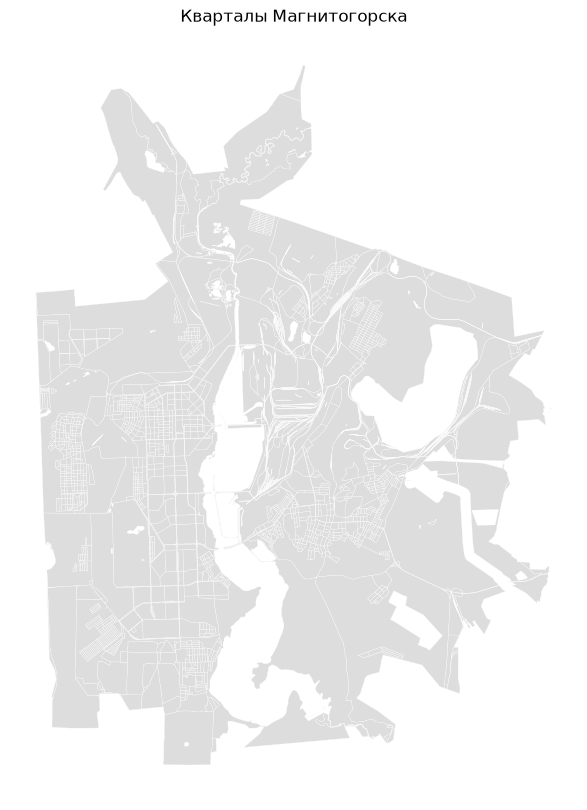

In [7]:
import geopandas as gpd
from pathlib import Path

data_dir = Path("data_magnitogorsk")

boundaries = gpd.read_file(data_dir / "boundaries.geojson")
roads = gpd.read_file(data_dir / "roads.geojson")
water = gpd.read_file(data_dir / "water.geojson")
railways = gpd.read_file(data_dir / "railways.geojson")
from blocksnet.blocks.cutting import cut_urban_blocks, preprocess_urban_objects

roads = roads.to_crs("EPSG:32640")
railways = railways.to_crs("EPSG:32640")
water = water.to_crs("EPSG:32640")
boundaries = boundaries.to_crs("EPSG:32640")
# Оставляем только линейные дорожные объекты
roads = roads[
    roads.geom_type.isin(["LineString", "MultiLineString"])
].copy()

# Оставляем только железнодорожные линии
railways = railways[
    railways.geom_type.isin(["LineString", "MultiLineString"])
].copy()

print("Дорожных линий:", len(roads))
print("Железнодорожных линий:", len(railways))
lines, polygons = preprocess_urban_objects(
    roads if not roads.empty else None,
    railways if not railways.empty else None,
    water if not water.empty else None,
)

blocks = cut_urban_blocks(boundaries, lines, polygons)
blocks = blocks[blocks.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
blocks = blocks[~blocks.is_empty].copy()
blocks = blocks.explode(index_parts=False).reset_index(drop=True)
blocks = blocks[blocks.geom_type == "Polygon"].copy()
blocks["site_area"] = blocks.area
blocks = blocks[blocks["site_area"] >= MIN_BLOCK_AREA_M2].copy()
blocks = blocks.reset_index(drop=True)
blocks.index.name = "block_id"

save_gdf(blocks, "blocks_initial", index_col="block_id")

print(f"Кварталов: {len(blocks)}")
print(f"Суммарная площадь кварталов: {blocks['site_area'].sum() / 1_000_000:.2f} км²")
print(blocks["site_area"].describe())
require(len(blocks) > 100, "Получилось слишком мало кварталов — проверьте исходные слои OSM")

ax = blocks.plot(figsize=(10, 10), color="#dddddd", edgecolor="white", linewidth=0.2)
ax.set_axis_off()
ax.set_title("Кварталы Магнитогорска")
plt.show()

## 4. Функциональные зоны и назначение земли

**Что делаем:** скачиваем полигоны `landuse` и сопоставляем их с типами `LandUse` из BlocksNet.

**Метрика:** `share` — доля квартала, занятая выбранным типом использования. `land_use` — преобладающий тип.

**Что узнаём:** где жилые, деловые, промышленные, рекреационные и специальные территории.

In [ ]:
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.enums import LandUse

functional_zones_path = DATA_DIR / "functional_zones.geojson"
if functional_zones_path.exists():
    functional_zones = load_gdf("functional_zones")
else:
    boundaries_4326 = boundaries.to_crs("EPSG:4326")
    functional_zones = ox.features_from_polygon(boundaries_4326.union_all(), {"landuse": True})
    require(not functional_zones.empty, "В OSM не найдены полигоны landuse")
    functional_zones = functional_zones.reset_index(drop=True)
    functional_zones = functional_zones[["geometry", "landuse"]].rename(columns={"landuse": "functional_zone"})
    functional_zones = functional_zones[functional_zones.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
    functional_zones["geometry"] = functional_zones.geometry.apply(make_valid)
    functional_zones = functional_zones.dropna(subset=["functional_zone"]).to_crs(CRS_PROJECTED)
    functional_zones["functional_zone"] = functional_zones["functional_zone"].astype(str)
    save_gdf(functional_zones, "functional_zones")

functional_zones = functional_zones.to_crs(CRS_PROJECTED)
functional_zones = functional_zones[functional_zones.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
functional_zones["geometry"] = functional_zones.geometry.apply(make_valid)
functional_zones = functional_zones.dropna(subset=["functional_zone"]).copy()
functional_zones["functional_zone"] = functional_zones["functional_zone"].astype(str)

rules = {
    "commercial": LandUse.BUSINESS,
    "industrial": LandUse.INDUSTRIAL,
    "cemetery": LandUse.SPECIAL,
    "garages": LandUse.INDUSTRIAL,
    "residential": LandUse.RESIDENTIAL,
    "retail": LandUse.BUSINESS,
    "grass": LandUse.RECREATION,
    "farmland": LandUse.AGRICULTURE,
    "construction": LandUse.SPECIAL,
    "brownfield": LandUse.INDUSTRIAL,
    "forest": LandUse.RECREATION,
    "recreation_ground": LandUse.RECREATION,
    "religious": LandUse.SPECIAL,
    "flowerbed": LandUse.RECREATION,
    "military": LandUse.SPECIAL,
    "landfill": LandUse.TRANSPORT,
    "railway": LandUse.TRANSPORT,
    "quarry": LandUse.INDUSTRIAL,
    "orchard": LandUse.AGRICULTURE,
    "meadow": LandUse.RECREATION,
    "village_green": LandUse.RECREATION,
    "plant_nursery": LandUse.AGRICULTURE,
    "greenhouse_horticulture": LandUse.AGRICULTURE,
    "basin": LandUse.RECREATION,
    "reservoir": LandUse.RECREATION,
    "winter_sports": LandUse.RECREATION,
}

blocks = assign_land_use(blocks, functional_zones, rules)
blocks.index.name = "block_id"
blocks["site_area"] = blocks.area

require(blocks["land_use"].notna().any(), "Не удалось назначить тип использования ни одному кварталу")
save_gdf(blocks, "blocks_land_use", index_col="block_id")

print(blocks["land_use"].value_counts(dropna=False))

ax = blocks.plot(figsize=(10, 10), color="#dddddd", edgecolor="white", linewidth=0.2)
blocks.dropna(subset=["land_use"]).plot(column="land_use", ax=ax, legend=True, categorical=True)
ax.set_axis_off()
ax.set_title("Преобладающее использование кварталов")
plt.show()

## 5. Пешеходный граф и время в пути

Сначала выполните **ячейку восстановления состояния** ниже. Она читает сохранённые
кварталы с block_id и границу; разделы 0–4 повторять не требуется. После перезапуска
ядра выполните эту ячейку, затем нужный этап. Его зависимости читаются из кэша.

Граф IduEdu: `get_accessibility_graph(..., graph_type="walk", walk_speed=5*1000/60)`.
Скорость задаётся **в метрах в минуту**, время рёбер — **в минутах**. Проверяются
EPSG-код, координаты, каждый вес и тип передвижения. Нулевые веса допустимы из-за
округления очень коротких рёбер IduEdu до 0.001 минуты.

Сеть по умолчанию запрещена. Если graph.pkl, buildings.geojson или schools.geojson
отсутствуют, этап остановится с объяснением. Для будущего получения только отсутствующих
исходников можно отдельно выполнить `ALLOW_NETWORK = True` после восстановления состояния.
Готовые файлы повторно не скачиваются. Самостоятельная проверка этого ноутбука
не запускала загрузок или полного расчёта города.


In [2]:
# 5.0. ВОССТАНОВЛЕНИЕ СОСТОЯНИЯ после перезапуска ядра (выполнить целиком).
MAGNITOGORSK_STATE_READY = False
from pathlib import Path
from datetime import datetime, timezone
from enum import Enum
import importlib.metadata
import json
import pickle
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
from pyproj import CRS
from shapely.validation import make_valid
from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.provision import competitive_provision
from blocksnet.config import service_types_config
from blocksnet.relations import (
    get_accessibility_graph, validate_accessibility_graph, validate_accessibility_matrix,
)

if importlib.metadata.version("blocksnet") != "1.0.0a9":
    raise RuntimeError("Этот ноутбук проверен для BlocksNet 1.0.0a9")
# Ячейка работает и из корня проекта, и при cwd=examples, и из вложенной папки.
_search_roots = (Path.cwd(), *Path.cwd().parents)
_data_candidates = [candidate for root in _search_roots for candidate in (
    root / "examples" / "data_magnitogorsk", root / "data_magnitogorsk",
) ]
DATA_DIR = next((candidate for candidate in _data_candidates
                 if (candidate / "boundaries.geojson").is_file()
                 and (candidate / "blocks_land_use.geojson").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Не найдена examples/data_magnitogorsk с boundaries.geojson и blocks_land_use.geojson")
DATA_DIR = DATA_DIR.resolve()
EXAMPLES_DIR = DATA_DIR.parent
BASE_DIR = EXAMPLES_DIR.parent
CRS_WGS84 = "EPSG:4326"
CITY_QUERY = "Магнитогорск, Челябинская область, Россия"
GRAPH_TYPE = "walk"
WALK_SPEED_KMH = 5.0
MIN_BLOCK_AREA_M2 = 100.0
LIVING_DEMAND_M2 = 30.0  # Допущение исходного ноутбука.
PROVISION_MAX_DEPTH = 1
SPACEMATRIX_CLUSTERS = 11
ALLOW_NETWORK = False
REFRESH_SAVED_DERIVED = False  # True: обновлять только производные файлы с резервными копиями.
MAX_CSV_CELLS = 40_000_000
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)
ox.settings.use_cache = True
ox.settings.log_console = False
warnings.filterwarnings("ignore")


def require(condition, message):
    if not condition:
        raise RuntimeError(message)


def json_safe(value):
    value = enum_text(value)
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, (list, tuple, dict, set)):
        return json.dumps(value, ensure_ascii=False, default=str)
    return None if pd.isna(value) else value


def enum_text(value):
    return value.value if isinstance(value, Enum) else value


def plain_table(frame):
    out = frame.copy()
    for column in out.columns:
        if column != "geometry" and out[column].dtype == object:
            out[column] = out[column].map(enum_text)
    return out


def clean_layer(layer, allowed_types):
    require(layer.crs is not None, "У слоя отсутствует CRS")
    rows, geometries = [], []
    def parts(geometry):
        if geometry is None or geometry.is_empty:
            return []
        if geometry.geom_type in allowed_types:
            return [geometry]
        if geometry.geom_type == "GeometryCollection":
            return [part for item in geometry.geoms for part in parts(item)]
        return []
    for i, geometry in enumerate(layer.geometry):
        if geometry is None or geometry.is_empty:
            continue
        geometry = geometry if geometry.is_valid else make_valid(geometry)
        for part in parts(geometry):
            rows.append(i)
            geometries.append(part)
    attributes = layer.iloc[rows].drop(columns=layer.geometry.name).reset_index(drop=True)
    out = gpd.GeoDataFrame(attributes, geometry=geometries, crs=layer.crs)
    require(not out.empty and out.is_valid.all(), "После очистки слой пуст или невалиден")
    return out


def read_geo(name, indexed=False):
    path = DATA_DIR / f"{name}.geojson"
    require(path.is_file(), f"Не найден {path.name}; выполните предыдущий этап")
    out = gpd.read_file(path)
    require(out.crs is not None, f"{name}: CRS не определена")
    if indexed:
        require("block_id" in out.columns, f"{name}: нет сохранённого block_id")
        out = out.set_index("block_id")
        ids = pd.to_numeric(out.index, errors="raise")
        require(np.isfinite(ids).all() and np.equal(ids, np.floor(ids)).all(), "block_id должны быть целыми")
        out.index = pd.Index(ids.astype(int), name="block_id")
        require(out.index.is_unique, f"{name}: повторяющиеся block_id")
    return out


def load_gdf(name, indexed=False):
    return read_geo(name, indexed=indexed)


def align(frame):
    require(frame.index.is_unique, "Повторяющиеся block_id")
    require(set(frame.index) == set(blocks.index), "Кэш не соответствует текущим block_id")
    return frame.loc[blocks.index].copy()


def read_table(name):
    path = DATA_DIR / f"{name}.parquet"
    if path.is_file():
        frame = pd.read_parquet(path)
    else:
        path = DATA_DIR / f"{name}.csv"
        require(path.is_file(), f"Нет {name}.parquet/.csv; выполните предыдущий этап")
        frame = pd.read_csv(path, index_col=0)
    frame.index = pd.Index(pd.to_numeric(frame.index, errors="raise").astype(int), name="block_id")
    return align(frame)


def _may_write(path):
    if not path.exists():
        return True
    refreshable = {"provision", "density", "results_blocks", "results_table", "summary", "run_meta"}
    if not REFRESH_SAVED_DERIVED or path.stem not in refreshable:
        return False
    from shutil import copy2
    backup_dir = DATA_DIR / "backups" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    backup_dir.mkdir(parents=True, exist_ok=True)
    copy2(path, backup_dir / path.name)
    print("Резервная копия:", backup_dir / path.name)
    return True


def save_table(frame, name):
    # По умолчанию файлы не заменяются; REFRESH_SAVED_DERIVED включает замену с резервной копией.
    out = plain_table(frame)
    parquet = DATA_DIR / f"{name}.parquet"
    if _may_write(parquet):
        out.to_parquet(parquet)
    csv = DATA_DIR / f"{name}.csv"
    if out.size <= MAX_CSV_CELLS and _may_write(csv):
        out.to_csv(csv, encoding="utf-8")


def save_gdf(frame, name, index_col="block_id"):
    path = DATA_DIR / f"{name}.geojson"
    if not _may_write(path):
        print(f"Существующий файл сохранён без изменений: {path.name}")
        return
    out = plain_table(frame)
    if index_col is not None:
        out.index.name = index_col
        out = out.reset_index()
    for column in out.columns:
        if column != out.geometry.name and out[column].dtype == object:
            out[column] = out[column].map(
                lambda v: json.dumps(v, ensure_ascii=False, default=str)
                if isinstance(v, (list, tuple, dict, set)) else v
            )
    out.to_file(path, driver="GeoJSON", encoding="utf-8")


def save_json_once(value, name):
    path = DATA_DIR / f"{name}.json"
    if _may_write(path):
        path.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding="utf-8")


def network_required(source):
    require(ALLOW_NETWORK, f"Нет {source}. Сеть запрещена (ALLOW_NETWORK=False). Нужны реальные исходные данные")


def map_column(frame, column, title, categorical=False, **kwargs):
    plot = blocks[["geometry"]].join(plain_table(frame[[column]]))
    ax = blocks.plot(figsize=(10, 10), color="#dddddd", edgecolor="white", linewidth=0.2)
    selected = plot[column].notna()
    if not categorical:
        selected &= np.isfinite(pd.to_numeric(plot[column], errors="coerce"))
    if selected.any():
        plot.loc[selected].plot(column=column, ax=ax, legend=True, categorical=categorical, **kwargs)
    ax.set_axis_off()
    ax.set_title(title)
    plt.show()
    if not selected.all():
        print(f"{column}: без окраски {int((~selected).sum())} кварталов (нет значения/недостижимость)")


boundaries = read_geo("boundaries").to_crs(CRS_WGS84)
boundaries_4326 = boundaries.copy()
CRS_PROJECTED = boundaries.estimate_utm_crs()
require(CRS_PROJECTED is not None and CRS_PROJECTED.is_projected, "Не определена метрическая CRS")
boundaries_projected = boundaries.to_crs(CRS_PROJECTED)
blocks = read_geo("blocks_land_use", indexed=True).to_crs(CRS_PROJECTED)
require(blocks.geom_type.eq("Polygon").all() and blocks.is_valid.all() and not blocks.is_empty.any(),
        "Для агрегации нужны валидные непустые Polygon")
blocks["site_area"] = blocks.area
require((blocks.site_area > 0).all(), "Кварталы с нулевой площадью")
print(f"Состояние восстановлено: {len(blocks)} кварталов, {CRS_PROJECTED}; сеть: {ALLOW_NETWORK}")


BUILDING_COLUMNS = ["population", "footprint_area", "build_floor_area", "living_area", "non_living_area"]
DENSITY_COLUMNS = ["fsi", "gsi", "mxi", "l", "osr", "share_living", "share_non_living"]
PROVISION_COLUMNS = ["demand", "demand_within", "demand_without", "demand_left", "capacity_within",
                     "capacity_without", "capacity_left", "provision_strong", "provision_weak"]


def aggregate_checkpoint(name, columns):
    out = align(read_geo(name, indexed=True).to_crs(CRS_PROJECTED))
    require(out.geometry.equals(blocks.geometry), f"{name}: геометрии не совпадают с кварталами")
    require(set(columns).issubset(out.columns), f"{name}: отсутствуют {columns}")
    for column in columns:
        out[column] = pd.to_numeric(out[column], errors="raise").astype(float)
        require(np.isfinite(out[column]).all() and out[column].ge(0).all(), f"{name}: неверные {column}")
    out["site_area"] = blocks.site_area
    return out


def get_buildings_blocks():
    return aggregate_checkpoint("buildings_blocks", BUILDING_COLUMNS)


def get_schools_blocks():
    return aggregate_checkpoint("schools_blocks", ["capacity"])


def checked_matrix(frame):
    from blocksnet.relations import validate_accessibility_matrix
    frame = frame.copy()
    frame.index = frame.index.astype(int)
    frame.columns = frame.columns.astype(int)
    require(frame.columns.is_unique, "В матрице повторяются столбцы")
    frame = align(frame)
    require(set(frame.columns) == set(blocks.index), "Столбцы матрицы не соответствуют кварталам")
    frame = frame.loc[blocks.index, blocks.index].astype(float)
    values = frame.to_numpy()
    require(not np.isnan(values).any() and (values >= 0).all(), "В матрице есть NaN/отрицательное время")
    require(np.allclose(np.diag(values), 0, atol=1e-5), "Диагональ матрицы должна быть нулевой")
    validate_accessibility_matrix(frame, blocks)
    frame.index.name = frame.columns.name = "block_id"
    return frame


def get_matrix():
    path = DATA_DIR / "accessibility_matrix.parquet"
    if path.is_file():
        return checked_matrix(pd.read_parquet(path))
    path = DATA_DIR / "accessibility_matrix.csv"
    require(path.is_file(), "Нет матрицы: выполните раздел 6")
    return checked_matrix(pd.read_csv(path, index_col=0))


def check_walk_graph(value):
    require(isinstance(value, nx.Graph) and value.number_of_edges() > 0, "Граф отсутствует или пуст")
    epsg = CRS.from_user_input(value.graph.get("crs")).to_epsg()
    require(epsg is not None, "Для схемы BlocksNet нужен EPSG-код CRS графа")
    value.graph["crs"] = int(epsg)  # Только метаданные: координаты не меняются.
    validate_accessibility_graph(value)
    require(value.graph.get("type") == "walk", "Ожидался пешеходный граф IduEdu")
    require(CRS(epsg).is_projected, "IduEdu ожидает проекционные координаты графа")
    speed = float(value.graph.get("walk_speed", np.nan))
    require(np.isclose(speed, WALK_SPEED_KMH * 1000 / 60), "Скорость кэша не соответствует 5 км/ч")
    for _, data in value.nodes(data=True):
        require(np.isfinite([float(data["x"]), float(data["y"])]).all(), "Невалидные координаты узла")
    for _, _, data in value.edges(data=True):
        weight = float(data["time_min"])
        require(np.isfinite(weight) and weight >= 0, "Ребро имеет отрицательное/нечисловое время")
        require(data.get("type") == "walk", "В графе найден иной тип ребра")
        if "length_meter" in data:
            require(np.isclose(weight, float(data["length_meter"]) / speed, atol=0.002),
                    "Время ребра не соответствует длине и скорости ходьбы")
    return value



def load_walk_graph():
    path = DATA_DIR / "graph.pkl"
    require(path.is_file(), "Нет graph.pkl: выполните раздел 5")
    with path.open("rb") as file:
        return check_walk_graph(pickle.load(file))


def reconcile_self_supply(frame):
    """Correct only capacity bookkeeping; do not change demand allocation or LP links."""
    frame = frame.copy()
    columns = ["capacity", "capacity_within", "capacity_without", "capacity_left", "demand"]
    require(set(columns).issubset(frame.columns), "Неполная таблица обеспеченности")
    require(np.isfinite(frame[columns].to_numpy(dtype=float)).all(), "Нечисловая ёмкость/спрос")
    gap = frame.capacity - frame.capacity_within - frame.capacity_without - frame.capacity_left
    if np.allclose(gap, 0):
        return frame
    self_supply = np.minimum(frame.demand, frame.capacity)
    require(np.allclose(gap, self_supply),
            "Баланс ёмкости не объясняется self_supply; нужна отдельная проверка исходного расчёта")
    frame["capacity_within"] = frame.capacity_within + gap
    require(np.allclose(frame.capacity, frame.capacity_within + frame.capacity_without + frame.capacity_left),
            "Баланс ёмкости не восстановлен")
    print("Исправлен учёт self_supply в capacity_within; распределение спроса не пересчитывалось")
    return frame


MAGNITOGORSK_STATE_READY = True
print("Ячейка 5.0 выполнена полностью; состояние готово для разделов 5, 9, 10 и 14")

Состояние восстановлено: 2910 кварталов, EPSG:32640; сеть: False
Ячейка 5.0 выполнена полностью; состояние готово для разделов 5, 9, 10 и 14


In [3]:
REFRESH_SAVED_DERIVED = True

In [ ]:
if not globals().get("MAGNITOGORSK_STATE_READY", False):
    raise RuntimeError("Сначала целиком выполните ячейку 5.0 «ВОССТАНОВЛЕНИЕ СОСТОЯНИЯ»")
from blocksnet.relations import get_accessibility_graph, validate_accessibility_graph



graph_path = DATA_DIR / "graph.pkl"
if graph_path.is_file():
    with graph_path.open("rb") as file:
        graph = pickle.load(file)
    graph = check_walk_graph(graph)
else:
    network_required("graph.pkl")
    graph = check_walk_graph(get_accessibility_graph(
        boundaries_4326, graph_type="walk", walk_speed=WALK_SPEED_KMH * 1000 / 60
    ))
    with graph_path.open("wb") as file:
        pickle.dump(graph, file)
graph_meta = {
    "source": "OpenStreetMap via IduEdu 0.4.1 get_walk_graph",
    "graph_type": graph.graph["type"], "walk_speed_m_per_min": graph.graph["walk_speed"],
    "walk_speed_kmh": graph.graph["walk_speed"] * 60 / 1000,
    "crs": graph.graph["crs"], "nodes": graph.number_of_nodes(), "edges": graph.number_of_edges(),
    "units": "minutes", "checked_at_utc": datetime.now(timezone.utc).isoformat(),
}
save_json_once(graph_meta, "graph_meta")
print(graph_meta)


## 6. Матрица доступности

BlocksNet 1.0.0a9 использует **representative_point()**, а не геометрические центроиды.
IduEdu рассчитывает кратчайшие пути по time_min и стандартные поправки на расстояние
от внутренней точки квартала до узла графа (5 км/ч). Матрица направленная, в минутах;
диагональ нулевая. Строки и столбцы строго согласуются с block_id. Используется float32
вместо float16 для запаса точности. Недостижимость сохраняется как **Infinity**:
конечное время не выдумывается. Историю старого кэша с уже заменёнными Infinity
нельзя восстановить из одной матрицы. Полный расчёт может быть длительным.


In [ ]:
from blocksnet.relations import calculate_accessibility_matrix

if (DATA_DIR / "accessibility_matrix.parquet").is_file() or (DATA_DIR / "accessibility_matrix.csv").is_file():
    acc_mx = get_matrix()
else:
    graph = load_walk_graph()
    print("Полная матрица может рассчитываться долго:", len(blocks), "×", len(blocks))
    acc_mx = checked_matrix(calculate_accessibility_matrix(
        blocks[["geometry"]], graph, weight_key="time_min", dtype=np.float32, max_workers=1
    ))
    save_table(acc_mx, "accessibility_matrix")
values = acc_mx.to_numpy()
print("Матрица:", acc_mx.shape, "| недостижимых пар:", int(np.isinf(values).sum()))
print("Максимум диагонали:", np.diag(values).max())
mask = ~np.eye(len(acc_mx), dtype=bool) & np.isfinite(values)
print(pd.Series(values[mask], name="time_min").describe())


## 7. Здания и население — локальный PBF

Выполните следующую кодовую ячейку. При наличии buildings_blocks.geojson используется
готовая агрегация. Иначе читается buildings.geojson; если его нет, здания извлекаются
через pyogrio/GDAL из `ural-fed-district-latest.osm.pbf`, слой **multipolygons**.
Он содержит и замкнутые ways, и отношения-мультиполигоны. Отбираются только объекты
с реальным тегом building (исключаются пустые значения и building=no/false/0).

В драйвере выделены building:levels и другие нужные теги. Остальные остаются в JSON
other_tags. Сохраняются тип OSM-объекта и его идентификатор: way и relation различаются.
Polygon и MultiPolygon сохраняются как единый объект; части одного здания не превращаются
в отдельные здания. Данные обрезаются по точной границе Магнитогорска и преобразуются
в **EPSG:32640**. Только после этого BlocksNet заполняет показатели площадей и населения
(30 м² жилой площади на человека — прежнее допущение). Результат сохраняется в buildings.geojson.

Overpass и другие сетевые источники не вызываются независимо от ALLOW_NETWORK.
GDAL может последовательно просканировать региональный PBF: bbox ограничивает
выходные объекты, но не гарантирует быстрое чтение. Это чтение выполняется только
при вашем запуске ячейки. Отсутствие зданий вызывает ошибку без фиктивных замен.
После перезапуска ядра сначала выполните ячейку восстановления состояния раздела 5.


In [ ]:
import sys

# Модуль лежит рядом с ноутбуком; работает и при запуске Jupyter из корня проекта.
if str(EXAMPLES_DIR.resolve()) not in sys.path:
    sys.path.insert(0, str(EXAMPLES_DIR.resolve()))
from magnitogorsk_pbf import load_local_osm_objects

from blocksnet.blocks.aggregation import aggregate_objects
from blocksnet.preprocessing.imputing import impute_buildings

if (DATA_DIR / "buildings_blocks.geojson").is_file():
    buildings_blocks = get_buildings_blocks()
else:
    require(blocks.crs.to_epsg() == 32640, "Кварталы должны быть в EPSG:32640")
    buildings = load_local_osm_objects("buildings", DATA_DIR, boundaries_4326)
    if "is_living" not in buildings:
        require("building" in buildings, "Для оценки населения нужен building или is_living")
        buildings["is_living"] = buildings["building"].isin(
            ["residential", "house", "apartments", "detached", "terrace", "dormitory"]
        )
    else:
        boolean_map = {True: True, False: False, 1: True, 0: False, "true": True, "false": False,
                       "True": True, "False": False, "1": True, "0": False}
        buildings["is_living"] = buildings["is_living"].map(boolean_map)
        require(buildings.is_living.notna().all(), "Нераспознанные значения is_living")
    buildings["is_living"] = buildings.is_living.astype(bool)
    if "number_of_floors" not in buildings:
        buildings["number_of_floors"] = buildings.get("building:levels", np.nan)
    for column in ["number_of_floors", *BUILDING_COLUMNS]:
        buildings[column] = pd.to_numeric(buildings.get(column, pd.Series(np.nan, index=buildings.index)), errors="coerce")
        buildings[column] = buildings[column].where(buildings[column] >= 0).astype(float)
    # BlocksNet заполняет population только для жилых зданий. Для нежилых
    # отсутствие населения означает 0, иначе после imputation останется NaN.
    non_living_missing_population = ~buildings.is_living & buildings.population.isna()
    buildings.loc[non_living_missing_population, "population"] = 0.0
    imputed = impute_buildings(buildings.copy(), default_living_demand=LIVING_DEMAND_M2)
    # Строгая схема BlocksNet отбрасывает теги: переносим вычисленные поля в исходную таблицу.
    for column in imputed.columns:
        if column != "geometry":
            buildings[column] = imputed[column]
    require(np.isfinite(buildings[BUILDING_COLUMNS].to_numpy()).all(), "Не восстановлены поля зданий")
    require((buildings.living_area <= buildings.build_floor_area + 1e-6).all(), "Жилая площадь больше поэтажной")
    save_gdf(buildings, "buildings", index_col=None)
    buildings_blocks, buildings_excess = aggregate_objects(
        blocks[["geometry"]], buildings[BUILDING_COLUMNS + ["geometry"]]
    )
    buildings_blocks.index.name = "block_id"
    buildings_blocks["site_area"] = blocks.site_area
    print("Зданий вне кварталов:", len(buildings_excess))
    save_gdf(buildings_blocks, "buildings_blocks")
    save_table(buildings_blocks.drop(columns="geometry"), "buildings_blocks")
print("Оценка населения:", buildings_blocks.population.sum())
map_column(buildings_blocks, "population", "Оценка населения по кварталам", cmap="viridis")


## 8. Школы — локальный PBF

Используются schools_blocks.geojson или schools.geojson, если они существуют.
При отсутствии кэша извлекаются реальные объекты **amenity=school** из обоих слоёв
локального PBF: **points** и **multipolygons**. amenity и capacity явно выделяются
в конфигурации GDAL; остальные теги сохраняются. Точки и полигоны обрезаются границей
города и приводятся к EPSG:32640. Никаких сетевых запросов и подмен объектов нет.

Отсутствующая ёмкость заполняется прежней функцией `impute_services(..., "school")`
по нормативам установленного BlocksNet. Уже известная ёмкость сохраняется.
Совпадение точки и полигона школы не означает автоматически один объект:
сохраняются реальные OSM-идентификаторы, учреждения не удаляются только по имени.


In [ ]:
import sys

# Модуль лежит рядом с ноутбуком; работает и при запуске Jupyter из корня проекта.
if str(EXAMPLES_DIR.resolve()) not in sys.path:
    sys.path.insert(0, str(EXAMPLES_DIR.resolve()))
from magnitogorsk_pbf import load_local_osm_objects

from blocksnet.blocks.aggregation import aggregate_objects
from blocksnet.preprocessing.imputing import impute_services

if (DATA_DIR / "schools_blocks.geojson").is_file():
    schools_blocks = get_schools_blocks()
else:
    require(blocks.crs.to_epsg() == 32640, "Кварталы должны быть в EPSG:32640")
    schools = load_local_osm_objects("schools", DATA_DIR, boundaries_4326)
    schools["capacity"] = pd.to_numeric(schools.get("capacity", pd.Series(np.nan, index=schools.index)), errors="coerce")
    schools["capacity"] = schools.capacity.where(schools.capacity >= 0).astype(float)
    imputed = impute_services(schools.copy(), service_type="school")
    schools["capacity"] = imputed.capacity
    require(np.isfinite(schools.capacity).all(), "Не восстановлена ёмкость школ")
    require(np.allclose(schools.capacity, np.round(schools.capacity)), "Ёмкость должна быть целым числом мест")
    save_gdf(schools, "schools", index_col=None)
    schools_blocks, schools_excess = aggregate_objects(blocks[["geometry"]], schools[["geometry", "capacity"]])
    schools_blocks.index.name = "block_id"
    print("Школ вне кварталов:", len(schools_excess))
    save_gdf(schools_blocks, "schools_blocks")
    save_table(schools_blocks.drop(columns="geometry"), "schools_blocks")
print("Суммарная ёмкость школ:", schools_blocks.capacity.sum())
map_column(schools_blocks, "capacity", "Ёмкость школ, мест", cmap="magma")


## 9. Обеспеченность школами

Нормативы читаются из `service_types_config["school"]` установленного BlocksNet.
Спрос округляется вверх внутри библиотеки; ёмкость — целое неотрицательное число мест.
`self_supply=True`, `max_depth=1` соответствуют стандартным параметрам 1.0.0a9.
При глубине 1 `provision_weak` и `provision_strong` совпадают: распределение за пределами
норматива не выполняется. При нулевом спросе доля не определена (NaN).
Недостижимые кварталы не получают искусственных связей.


Норматив: 120 мест на 1000 жителей; 15 мин; глубина 1
Исправлен учёт self_supply в capacity_within; распределение спроса не пересчитывалось
Резервная копия: C:\Users\lenovo\Desktop\вуз\итмо\ИИ\python-package-boilerplate\examples\data_magnitogorsk\backups\20261103_032918_658531\provision.parquet
Резервная копия: C:\Users\lenovo\Desktop\вуз\итмо\ИИ\python-package-boilerplate\examples\data_magnitogorsk\backups\20261103_032918_680659\provision.csv
            demand     capacity  provision_strong  provision_weak
count  2910.000000  2910.000000         679.00000       679.00000
mean      9.344674     8.591065           0.26055         0.26055
std      53.006584    70.382307           0.43718         0.43718
min       0.000000     0.000000           0.00000         0.00000
25%       0.000000     0.000000           0.00000         0.00000
50%       0.000000     0.000000           0.00000         0.00000
75%       0.000000     0.000000           1.00000         1.00000
max    1259.000000  1500

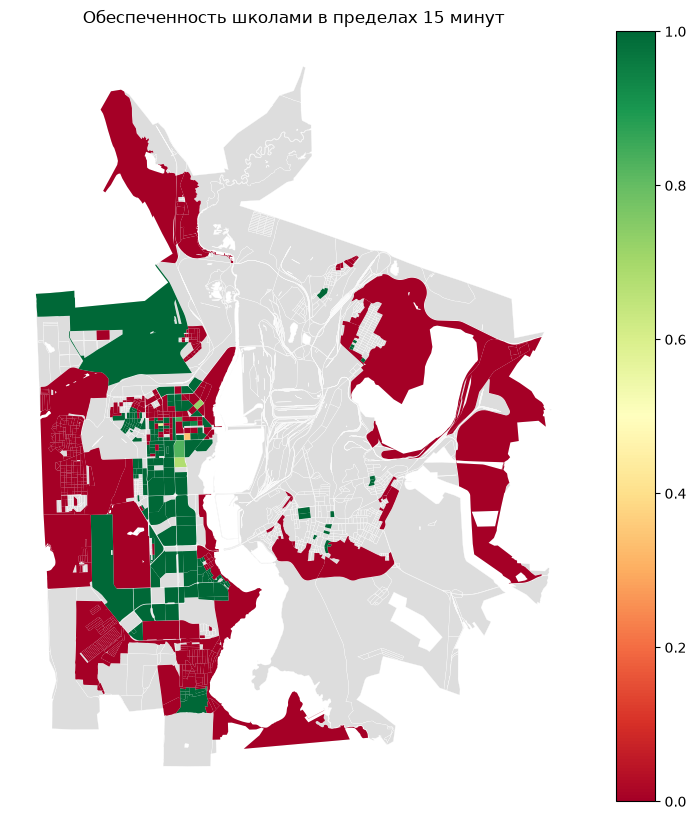

provision_strong: без окраски 2231 кварталов (нет значения/недостижимость)


In [4]:
if not globals().get("MAGNITOGORSK_STATE_READY", False):
    raise RuntimeError("Сначала целиком выполните ячейку 5.0 «ВОССТАНОВЛЕНИЕ СОСТОЯНИЯ»")
from blocksnet.analysis.provision import competitive_provision
from blocksnet.config import service_types_config

school_config = service_types_config["school"]
school_demand = int(school_config["demand"])
school_accessibility = int(school_config["accessibility"])
print("Норматив:", school_demand, "мест на 1000 жителей;", school_accessibility, "мин; глубина", PROVISION_MAX_DEPTH)
if (DATA_DIR / "provision.parquet").is_file() or (DATA_DIR / "provision.csv").is_file():
    prov_df = read_table("provision")
else:
    buildings_blocks = get_buildings_blocks()
    schools_blocks = get_schools_blocks()
    acc_mx = get_matrix()
    provision_input = buildings_blocks[["population"]].join(schools_blocks[["capacity"]])
    require(np.isfinite(provision_input.to_numpy()).all(), "Пустые/бесконечные population/capacity")
    require(np.allclose(provision_input.capacity, np.round(provision_input.capacity)), "capacity должна быть целой")
    provision_input["capacity"] = provision_input.capacity.round().astype(int)
    prov_df, links_df = competitive_provision(
        provision_input, acc_mx, accessibility=school_accessibility, demand=school_demand,
        self_supply=True, max_depth=PROVISION_MAX_DEPTH,
    )
    prov_df.index.name = "block_id"
    prov_df.loc[prov_df.demand == 0, ["provision_strong", "provision_weak"]] = np.nan
    prov_df = reconcile_self_supply(prov_df)
    save_table(prov_df, "provision")
    if not links_df.empty:
        save_table(links_df.reset_index(), "provision_links")
# В 1.0.0a9 _supply_self не увеличивает capacity_within. Восстанавливаем только баланс.
prov_df = reconcile_self_supply(prov_df)
prov_df.loc[prov_df.demand == 0, ["provision_strong", "provision_weak"]] = np.nan
if REFRESH_SAVED_DERIVED:
    prov_df = reconcile_self_supply(prov_df)
    save_table(prov_df, "provision")
require(set(PROVISION_COLUMNS).issubset(prov_df.columns), "Неполный кэш обеспеченности")
for column in ["provision_strong", "provision_weak"]:
    require(prov_df[column].dropna().between(0, 1).all(), f"{column} вне [0, 1]")
print(prov_df[["demand", "capacity", "provision_strong", "provision_weak"]].describe())
map_column(prov_df, "provision_strong", f"Обеспеченность школами в пределах {school_accessibility} минут",
           cmap="RdYlGn", vmin=0, vmax=1)


## 10. Показатели плотности

Формулы установленного BlocksNet: FSI = поэтажная площадь / площадь квартала;
GSI = площадь застройки / площадь квартала (0…1); MXI = жилая / поэтажная площадь (0…1);
L = поэтажная / площадь застройки (нижняя граница 1);
OSR = (площадь квартала − площадь застройки) / поэтажная площадь.
`share_living` и `share_non_living` в 1.0.0a9 делятся на **площадь застройки**;
это коэффициенты, которые могут превышать 1, а не доли поэтажной площади.
NaN и Infinity от деления на ноль сохраняются в расчётной таблице. На карте такие
кварталы серые. Морфотипы рассчитываются только для застроенных кварталов.


Резервная копия: C:\Users\lenovo\Desktop\вуз\итмо\ИИ\python-package-boilerplate\examples\data_magnitogorsk\backups\20261103_032929_408280\density.parquet
Резервная копия: C:\Users\lenovo\Desktop\вуз\итмо\ИИ\python-package-boilerplate\examples\data_magnitogorsk\backups\20261103_032929_422478\density.csv
               fsi          gsi          mxi            l          osr  share_living  share_non_living
count  2910.000000  2910.000000  1494.000000  1494.000000  2910.000000   1494.000000       1494.000000
mean      0.087391     0.060661     0.284421     1.309793          inf      0.403457          0.906336
std       0.182642     0.087382     0.370807     0.943664          NaN      0.695587          0.764177
min       0.000000     0.000000     0.000000     1.000000    -0.777987      0.000000          0.100000
25%       0.000000     0.000000     0.000000     1.000000     7.902063      0.000000          0.422019
50%       0.002749     0.002680     0.000000     1.000000   362.716900      0.

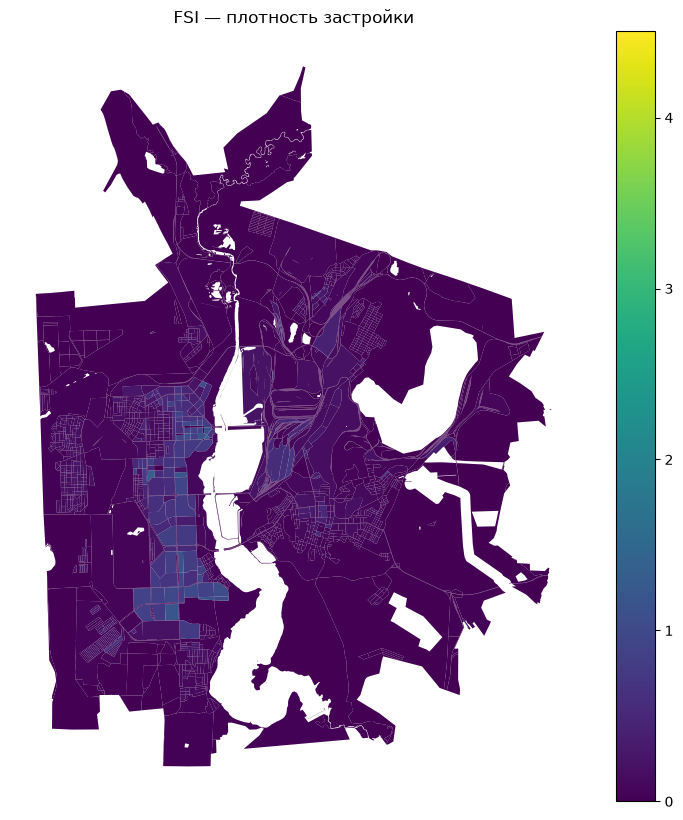

In [5]:
if not globals().get("MAGNITOGORSK_STATE_READY", False):
    raise RuntimeError("Сначала целиком выполните ячейку 5.0 «ВОССТАНОВЛЕНИЕ СОСТОЯНИЯ»")
from blocksnet.analysis.indicators import calculate_density_indicators

if not REFRESH_SAVED_DERIVED and ((DATA_DIR / "density.parquet").is_file() or (DATA_DIR / "density.csv").is_file()):
    density_df = read_table("density")
else:
    buildings_blocks = get_buildings_blocks()
    density_input = buildings_blocks[BUILDING_COLUMNS].copy()
    density_input["site_area"] = blocks.site_area
    density_df = calculate_density_indicators(density_input)
    # Неопределённые отношения при отсутствии застройки сохраняем как NaN/inf.
    density_df.index.name = "block_id"
    save_table(density_df, "density")
require(set(DENSITY_COLUMNS).issubset(density_df.columns), "Неполный кэш плотности")
print(density_df[DENSITY_COLUMNS].describe())
map_column(density_df, "fsi", "FSI — плотность застройки", cmap="viridis")


## 11. Морфотипы Spacematrix

**Что делаем:** кластеризуем застроенные кварталы по `l`, `fsi`, `mxi` и подписываем кластеры.

**Метрики:** `cluster` — номер кластера, `morphotype` — текстовое описание (например, «mid-rise high-density residential»).

**Что узнаём:** какие типы застройки распространены в городе: малоэтажная, среднеэтажная, микрорайонная, центральная и т. п.

In [ ]:
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes

if (DATA_DIR / "spacematrix.parquet").is_file() or (DATA_DIR / "spacematrix.csv").is_file():
    spacematrix_df = read_table("spacematrix")
    cluster_path = DATA_DIR / "spacematrix_clusters.parquet"
    require(cluster_path.is_file(), "Нет spacematrix_clusters.parquet")
    spacematrix_clusters = pd.read_parquet(cluster_path)
else:
    density_df = read_table("density")
    morph_input = density_df[["l", "fsi", "mxi"]].copy()
    developed = morph_input.fsi > 0
    require(np.isfinite(morph_input.loc[developed].to_numpy()).all(), "Невалидные показатели застроенных кварталов")
    spacematrix_df = pd.DataFrame(index=blocks.index, columns=["cluster", "morphotype"])
    if developed.any():
        unique_count = len(morph_input.loc[developed].drop_duplicates())
        n_clusters = min(SPACEMATRIX_CLUSTERS, int(developed.sum()), unique_count)
        classified, spacematrix_clusters = get_spacematrix_morphotypes(
            morph_input.loc[developed], n_clusters=n_clusters, random_state=42
        )
        spacematrix_df.loc[classified.index, ["cluster", "morphotype"]] = classified[["cluster", "morphotype"]]
    else:
        spacematrix_clusters = pd.DataFrame(columns=["l", "fsi", "mxi", "morphotype"])
        print("Нет застроенных кварталов: морфотип не определён")
    spacematrix_df["cluster"] = pd.to_numeric(spacematrix_df.cluster, errors="coerce")
    spacematrix_df.index.name = "block_id"
    save_table(spacematrix_df, "spacematrix")
    save_table(spacematrix_clusters, "spacematrix_clusters")
map_column(spacematrix_df, "morphotype", "Морфотипы Spacematrix", categorical=True)


## 12. Морфотипы Strelka

**Что делаем:** применяем к кварталам правила классификации Strelka по этажности, плотности и доле жилья.

**Метрика:** `morphotype` — название типа застройки по методике Strelka.

**Что узнаём:** как типы застройки соотносятся с привычными названиями: «советский микрорайон», «современный микрорайон», «центральная модель», «индивидуальная застройка» и др.

In [ ]:
from blocksnet.analysis.morphotypes import get_strelka_morphotypes

if (DATA_DIR / "strelka.parquet").is_file() or (DATA_DIR / "strelka.csv").is_file():
    strelka_df = read_table("strelka")
else:
    density_df = read_table("density")
    morph_input = density_df[["l", "fsi", "mxi"]].copy()
    developed = morph_input.fsi > 0
    require(np.isfinite(morph_input.loc[developed].to_numpy()).all(), "Невалидные показатели застроенных кварталов")
    strelka_df = pd.DataFrame(index=blocks.index, columns=["morphotype"])
    if developed.any():
        classified = get_strelka_morphotypes(morph_input.loc[developed])
        strelka_df.loc[classified.index, "morphotype"] = classified.morphotype
    strelka_df.index.name = "block_id"
    save_table(strelka_df, "strelka")
print(plain_table(strelka_df).morphotype.value_counts(dropna=False))
map_column(strelka_df, "morphotype", "Морфотипы Strelka", categorical=True)


## 13. Площадная доступность

**Что делаем:** считаем средневзвешенное по площади время пути от каждого квартала до всех остальных кварталов.

**Метрика:** `area_accessibility` — среднее время в минутах, взвешенное по площади кварталов.

**Что узнаём:** насколько квартал «встроен» в город. Чем меньше значение, тем быстрее из квартала можно добраться до разных частей города.

In [ ]:
from blocksnet.analysis.network.accessibility import area_accessibility

if (DATA_DIR / "area_accessibility.parquet").is_file() or (DATA_DIR / "area_accessibility.csv").is_file():
    area_acc = read_table("area_accessibility")
else:
    acc_mx = get_matrix()
    area_acc = area_accessibility(acc_mx, blocks[["site_area"]], out=True)
    area_acc.index.name = "block_id"
    save_table(area_acc, "area_accessibility")
print(area_acc.area_accessibility.describe())
map_column(area_acc, "area_accessibility", "Средневзвешенная доступность, минуты", cmap="plasma")


## 14. Итоговый слой и сводка

**Что делаем:** собираем все показатели в один GeoJSON и одну таблицу, сохраняем сводку и паспорт запуска.

**Что смотреть в результатах:**
- `results_blocks.geojson` — итоговая карта для QGIS;
- `results_table.csv` — все показатели по кварталам;
- `summary.csv` — средние, медианные и крайние значения;
- `run_meta.json` — параметры запуска, источник графа и число объектов.

In [6]:
if not globals().get("MAGNITOGORSK_STATE_READY", False):
    raise RuntimeError("Сначала целиком выполните ячейку 5.0 «ВОССТАНОВЛЕНИЕ СОСТОЯНИЯ»")
from blocksnet.config import service_types_config

buildings_blocks = get_buildings_blocks()
schools_blocks = get_schools_blocks()
prov_df = read_table("provision")
density_df = read_table("density")
spacematrix_df = read_table("spacematrix")
strelka_df = read_table("strelka")
area_acc = read_table("area_accessibility")
results = plain_table(blocks.copy())
if "count" in buildings_blocks:
    results["count_buildings"] = buildings_blocks["count"]
if "count" in schools_blocks:
    results["count_schools"] = schools_blocks["count"]
for frame, columns in (
    (buildings_blocks, BUILDING_COLUMNS), (schools_blocks, ["capacity"]),
    (prov_df, PROVISION_COLUMNS), (density_df, DENSITY_COLUMNS),
):
    results = results.join(frame[columns], validate="one_to_one")
results = results.join(spacematrix_df[["cluster", "morphotype"]].rename(
    columns={"cluster": "spacematrix_cluster", "morphotype": "spacematrix_morphotype"}), validate="one_to_one")
results = results.join(strelka_df[["morphotype"]].rename(columns={"morphotype": "strelka_morphotype"}), validate="one_to_one")
results = results.join(area_acc[["area_accessibility"]], validate="one_to_one")
results.index.name = "block_id"
# GeoJSON не представляет Infinity: экспортная копия содержит null и отдельный флаг.
results["area_accessibility_unreachable"] = np.isinf(results.area_accessibility)
for column in results.select_dtypes(include=[np.number]).columns:
    results[column] = results[column].replace([np.inf, -np.inf], np.nan)
save_gdf(results, "results_blocks")
results_table = results.drop(columns="geometry")
save_table(results_table, "results_table")
numeric = results_table.select_dtypes(include=[np.number])
summary = numeric.describe().T.reset_index().rename(columns={"index": "metric", "50%": "median"})
summary = summary[["metric", "count", "mean", "median", "min", "max"]]
save_table(summary, "summary")
graph_meta_path = DATA_DIR / "graph_meta.json"
require(graph_meta_path.is_file(), "Нет graph_meta.json: выполните раздел 5")
graph_meta = json.loads(graph_meta_path.read_text(encoding="utf-8"))
run_meta = {
    "city": CITY_QUERY, "blocksnet": importlib.metadata.version("blocksnet"), "blocks": len(blocks),
    "crs": str(CRS_PROJECTED), "graph": graph_meta,
    "population_living_demand_m2": LIVING_DEMAND_M2, "school_norms": dict(service_types_config["school"]),
    "provision_max_depth": PROVISION_MAX_DEPTH, "spacematrix_requested_clusters": SPACEMATRIX_CLUSTERS,
    "matrix_points": "representative_point", "unreachable_pairs": "History of existing matrix not verifiable from values alone",
    "units": {"accessibility": "minutes", "areas": "m2", "population": "estimated people", "capacity": "places"},
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
}
save_json_once(run_meta, "run_meta")
print("Готово. Итог:", DATA_DIR / "results_blocks.geojson")
print(summary.to_string(index=False))


Резервная копия: C:\Users\lenovo\Desktop\вуз\итмо\ИИ\python-package-boilerplate\examples\data_magnitogorsk\backups\20261103_032940_300752\results_blocks.geojson
Резервная копия: C:\Users\lenovo\Desktop\вуз\итмо\ИИ\python-package-boilerplate\examples\data_magnitogorsk\backups\20261103_032940_816916\results_table.parquet
Резервная копия: C:\Users\lenovo\Desktop\вуз\итмо\ИИ\python-package-boilerplate\examples\data_magnitogorsk\backups\20261103_032940_836545\results_table.csv
Резервная копия: C:\Users\lenovo\Desktop\вуз\итмо\ИИ\python-package-boilerplate\examples\data_magnitogorsk\backups\20261103_032940_947478\summary.parquet
Резервная копия: C:\Users\lenovo\Desktop\вуз\итмо\ИИ\python-package-boilerplate\examples\data_magnitogorsk\backups\20261103_032940_953865\summary.csv
Резервная копия: C:\Users\lenovo\Desktop\вуз\итмо\ИИ\python-package-boilerplate\examples\data_magnitogorsk\backups\20261103_032940_961166\run_meta.json
Готово. Итог: C:\Users\lenovo\Desktop\вуз\итмо\ИИ\python-package-bo

In [7]:
REFRESH_SAVED_DERIVED = False

## 15. Перезапуск и ограничения

После перезапуска выполните **ячейку восстановления состояния раздела 5**, затем
нужный этап. Он читает зависимости из GeoJSON/Parquet/CSV. Если результата предыдущего
этапа нет, выполните его сначала. Готовые файлы автоматически не перезаписываются
и не удаляются. Для пересчёта с другими параметрами используйте новую папку результатов
с копиями исходников и последовательно выполните зависимые этапы. Кэш проверяется
по структуре и идентификаторам; соответствие его давности текущим источникам не гарантируется.

В разделах 7–15 отсутствующие здания и школы извлекаются только из локального PBF
через magnitogorsk_pbf.py. ALLOW_NETWORK на эти разделы не влияет: сетевых веток нет.
При отсутствии нужных объектов этап останавливается без подмены данных. Не используйте «Выполнить всё» для
короткой проверки: граф и полная матрица могут рассчитываться долго.

Население оценочное: 30 м² жилой площади на человека — допущение исходного ноутбука.
Недостающие этажность и ёмкость заполняются функциями BlocksNet, не официальной статистикой.
OSM может содержать точку и полигон одной школы: перед итоговой интерпретацией проверьте
такие совпадения; автоматически удалять учреждения по одному имени ненадёжно.

Задание преподавателя и эталонный pipeline.ipynb локально не найдены. Сигнатуры, схемы
и формулы проверены по исходникам установленного BlocksNet 1.0.0a9 и IduEdu 0.4.1.
Строгое совпадение с недоступным заданием не утверждается. Все показатели сохранены.

### Обновление старого кэша без графа, PBF и матрицы

1. Перезапустите ядро и выполните целиком кодовую ячейку 5.0 `ВОССТАНОВЛЕНИЕ СОСТОЯНИЯ`
   (8-я кодовая ячейка ноутбука). Ячейку построения графа сразу после неё не выполняйте.
2. В отдельной ячейке задайте `REFRESH_SAVED_DERIVED = True`.
3. Выполните раздел 9: он прочитает provision из кэша и проверит учёт self_supply, не решая LP заново.
4. Выполните раздел 10: только арифметические формулы плотности по buildings_blocks.geojson.
5. Выполните раздел 14: сборка итогового слоя, сводки и паспорта из готовых файлов.
6. Задайте `REFRESH_SAVED_DERIVED = False`.

Старые версии заменяемых производных файлов копируются в data_magnitogorsk/backups/.
Граф, матрица, исходные геоданные и результаты разделов 1–8 не заменяются.
Разделы 11–12 повторять не нужно: при этой корректировке показатели застроенных кварталов,
по которым вычислялись морфотипы, не изменяются.
Суммированные пересечения landuse могут превышать 1 при перекрытии полигонов OSM:
это особенность assign_land_use; значения не обрезаются молча до 1.